# Trabajo Integrador: un RAG sobre seguridad en IA generativa

**Juan Cifuentes. Tecnicatura Superior en Ciencias de Datos e Inteligencia Artificial, IFTS N.º 24**
* **Materia:** Técnicas de Procesamiento de Habla (Procesamiento de Lenguaje Natural), segundo cuatrimestre de 2026

---

## Cuaderno 02: Guardar y consultar fragmentos

## Objetivo

Usar `bge-m3` y Chroma con LangChain para buscar evidencia en los tres documentos y revisar sus distancias y fuentes.

## Antes del índice

Hay que ejecutar `ollama pull bge-m3` una sola vez, fuera del cuaderno. `bge-m3` convierte en vectores, en español y otros idiomas, tanto los fragmentos como las preguntas, y para comparar las dos cosas tienen que salir del mismo modelo.

In [1]:
import os
from pathlib import Path

from dotenv import load_dotenv
from langchain_chroma import Chroma
from langchain_community.document_loaders import PyPDFLoader
from langchain_ollama import OllamaEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from utils_visualizacion import dibujar_barras

load_dotenv(".env")
nombre_embeddings = os.getenv("OLLAMA_EMBEDDING_MODEL", "bge-m3")
embeddings = OllamaEmbeddings(model=nombre_embeddings)
consulta = "¿Qué es la inyección de prompt?"
vector_consulta = embeddings.embed_query(consulta)
print("Dimensiones del vector:", len(vector_consulta))

C:\Users\JUANK\AppData\Local\Temp\ipykernel_1752\3642512258.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


Dimensiones del vector: 1024


## Una colección que puede volver a abrirse

| Decisión | Valor | Motivo |
|---|---|---|
| `persist_directory` | `chroma_db_bge_m3` | Permite cerrar y volver a abrir el índice. No se sube a GitHub. |
| `collection_name` | Incluye el modelo | Evita confundir vectores hechos con modelos distintos. |
| `chunk_size` / `chunk_overlap` | 800 / 120 | El mismo corte del cuaderno 01. |

Si cambia el corpus, el modelo o el corte, hay que crear una colección nueva o reconstruir el índice. Una colección vieja puede devolver resultados que parecen válidos pero están desactualizados.

In [2]:
ruta_owasp = Path("datos/owasp_top10_llm_2025.pdf")
ruta_aesia = Path("datos/aesia_guia11_ciberseguridad.pdf")
ruta_incibe = Path("datos/incibe_medidas_ia_frontera.pdf")
documentos = PyPDFLoader(str(ruta_owasp)).load()
documentos += PyPDFLoader(str(ruta_aesia)).load()
documentos += PyPDFLoader(str(ruta_incibe)).load()

divisor = RecursiveCharacterTextSplitter(chunk_size=800, chunk_overlap=120)
fragmentos = divisor.split_documents(documentos)
nombre_coleccion = "seguridad_ia_" + nombre_embeddings.replace(":", "_").replace("-", "_")
almacen = Chroma(
    collection_name=nombre_coleccion,
    embedding_function=embeddings,
    persist_directory="chroma_db_bge_m3",
)

identificadores = []
for numero in range(len(fragmentos)):
    identificadores.append(f"fragmento_{numero}")

# Los mismos identificadores reemplazan estos fragmentos si repetís la celda.
almacen.add_documents(documents=fragmentos, ids=identificadores)
print("Fragmentos del corpus:", len(fragmentos))
print("Registros en esta colección:", len(almacen.get()["ids"]))

Fragmentos del corpus: 480
Registros en esta colección: 480


## Buscar antes de pedirle una respuesta al modelo

`k=3` devuelve los tres vecinos más cercanos. `similarity_search_with_score` entrega pares `(Document, distancia)`: **una distancia menor significa más cercano** en esta colección, no más verdadero. Miro el texto de cada resultado antes de confiar en el orden.


Resultado 1: owasp_top10_llm_2025.pdf; página (desde 0): 7
Distancia: 0.598
OWASP Top 10 para Aplicaciones de LLM 2025
4genai.owasp.org
LLM01:2025 Inyección de prompt
Descripción
Una vulnerabilidad de inyección de prompt ocurre cuando los prompts del usuario alteran el
comportamiento o la salida del LLM en formas no intencionadas. Estas entradas pueden
afectar al modelo incluso si son imperceptibles para los humanos, por l

Resultado 2: owasp_top10_llm_2025.pdf; página (desde 0): 7
Distancia: 0.635
Inyección de prompt directa
Las inyecciones de prompt directas se producen cuando la entrada de un prompt de
usuario altera directamente el comportamiento del modelo de forma no intencionada o
inesperada. La entrada puede ser intencional (es decir, un actor malicioso
deliberadamente elabora un prompt para explotar el modelo) o no intencional (es de

Resultado 3: owasp_top10_llm_2025.pdf; página (desde 0): 2
Distancia: 0.641
LLM01:2025 Inyección de prompt  .  .  .  .  .  .  .  .  .  .  .  . 

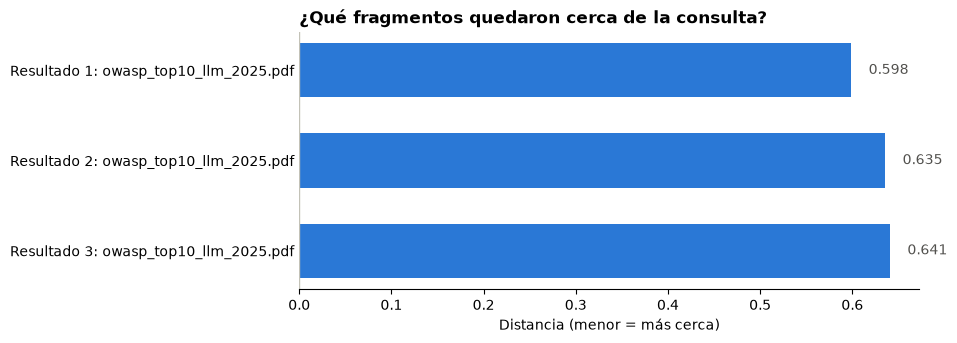

In [3]:
hallazgos = almacen.similarity_search_with_score(query=consulta, k=3)
etiquetas = []
distancias = []

for numero in range(len(hallazgos)):
    documento, distancia = hallazgos[numero]
    fuente = Path(str(documento.metadata["source"])).name
    pagina = documento.metadata.get("page")
    print(f"\nResultado {numero + 1}: {fuente}; página (desde 0): {pagina}")
    print("Distancia:", round(distancia, 3))
    print(documento.page_content[:350])
    etiquetas.append(f"Resultado {numero + 1}: {fuente}")
    distancias.append(distancia)

dibujar_barras(
    etiquetas=etiquetas,
    valores=distancias,
    titulo="¿Qué fragmentos quedaron cerca de la consulta?",
    etiqueta_eje_x="Distancia (menor = más cerca)",
    formato="{:.3f}",
)

## Lo que encontré al probar tres consultas

Cambiando la consulta de la primera celda y volviendo a ejecutar:

- **«¿Qué es la inyección de prompt?»**: los dos primeros resultados son de OWASP, página 8, con la definición y la inyección directa (distancias 0,598 y 0,635). El tercero es el índice de OWASP (página 3, distancia 0,641), que tiene las mismas palabras pero ningún contenido útil.
- **«¿Cómo puede un atacante manipular las instrucciones que recibe un chatbot?»**, la misma idea con otras palabras: encontró escenarios de inyección directa (página 10) y de sufijo adversario (página 11), pero también un caso de un chatbot médico que da información errónea (página 41), que comparte la palabra «chatbot» y no tiene que ver. Las distancias subieron a 0,72–0,80.
- **«¿Cuántos ataques de inyección de prompt hubo en Argentina en 2025?»**, que el corpus no puede responder: devolvió igual tres fragmentos sobre inyección de prompt (el índice, la definición y la inyección indirecta), con distancias de 0,82 a 0,998. Ninguno tiene el dato.

Chroma siempre devuelve algún vecino, aunque ninguno sirva. Las distancias más altas dan una pista, pero no alcanzan para que el sistema se abstenga solo: eso lo tiene que resolver el pedido al modelo en el cuaderno 03.

## Glosario

| Término | Qué significa acá |
|---|---|
| **Embedding** | Vector que representa el texto según un modelo específico. |
| **Índice** | Conjunto de vectores y textos guardados para buscar vecinos. |
| **Distancia** | Medida de cercanía dentro del índice. Por sí sola no indica que la respuesta sea verdadera o suficiente. |
| **k** | Cantidad de fragmentos que se le piden al buscador. |
| **Colección** | Conjunto de fragmentos y metadatos dentro de Chroma. |